# **Procesamiento de Imágenes Digitales – Proyecto Final (PC5)**
## Enfoque 2: Detección y Estimación de Ocupación de Estacionamientos con YOLOv8s

* **Curso:** Procesamiento de Imágenes Digitales
* **Docente:** MSc. Pedro Crisóstomo
* **Grupo:** 1
* **Integrantes:** Jean Piero Barboza, Jhosep Gutiérrez, Fabiola Fuentes

---

### Objetivo del Notebook
Implementar, entrenar y evaluar un modelo de aprendizaje profundo (**YOLOv8s**) sobre el dataset **PKLot** para localizar y clasificar de forma autónoma cajones de estacionamiento (`libre` vs. `ocupado`), superando la sensibilidad a sombras largas y la dependencia de mapas de coordenadas fijas del enfoque clásico.

---
## 1. Configuración del Entorno y Descarga del Dataset (PKLot)
Se instalan las librerías `ultralytics` (arquitectura YOLOv8) y `roboflow` para descargar el conjunto de datos **PKLot** (Universidade Federal do Paraná y PUC-Paraná). El dataset incluye capturas diurnas de 3 estacionamientos (`PUCPR`, `UFPR04` y `UFPR05`) bajo clima soleado, nublado y lluvioso, con anotaciones binarias por cajón.


In [ ]:
!pip install ultralytics roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 9.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 26.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="CODSlRSXYSzqJL0A7PWb")
project = rf.workspace("zoja-scekic").project("pklot-vsh7g")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PKLot-1 in yolov8:: 100%|██████████| 25292/25292 [00:03<00:00, 7986.65it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Entrenamiento del Modelo YOLOv8s
Se selecciona la variante **YOLOv8s (*small*)** por ofrecer el mejor equilibrio entre precisión en cajones lejanos y costo computacional. Los hiperparámetros configurados son:

| Parámetro | Valor |
| :--- | :--- |
| **Arquitectura** | YOLOv8s (*anchor-free*) |
| **Resolución de entrada** | $640 \times 640$ píxeles |
| **Dataset utilizado** | 10 247 imágenes (70% train / 20% val / 10% test) |
| **Épocas** | 50 |
| **Tamaño de lote (*batch*)** | 16 |

In [ ]:
from ultralytics import YOLO

# Cargar el modelo Small (el mejor equilibrio para visión aérea en Colab)
model = YOLO('yolov8s.pt')

# Iniciar entrenamiento con 50 épocas
resultados = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project='Proyecto_Estacionamientos',
    name='modelo_small_50',
    plots=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PKLot-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=modelo_small_50, nbs=64, nms=None, opset=None, optimize=False,

## 3. Evaluación Cuantitativa: Pérdidas, Curva PR y Matriz de Confusión
**Análisis del entrenamiento:** A lo largo de las 50 épocas se observa una convergencia limpia y sin indicios de sobreajuste. `Box loss` desciende de ~1.38 a ~0.22, `Classification loss` de ~0.89 a ~0.16 y `DFL loss` de ~1.08 a ~0.77, destacando un descenso adicional en la época 40 (cuando YOLOv8 desactiva el *data augmentation* de mosaico para afinar la localización). En paralelo, las métricas de validación (Precisión, Recall y mAP50) se estabilizan cerca de 1.00 desde la época 15.

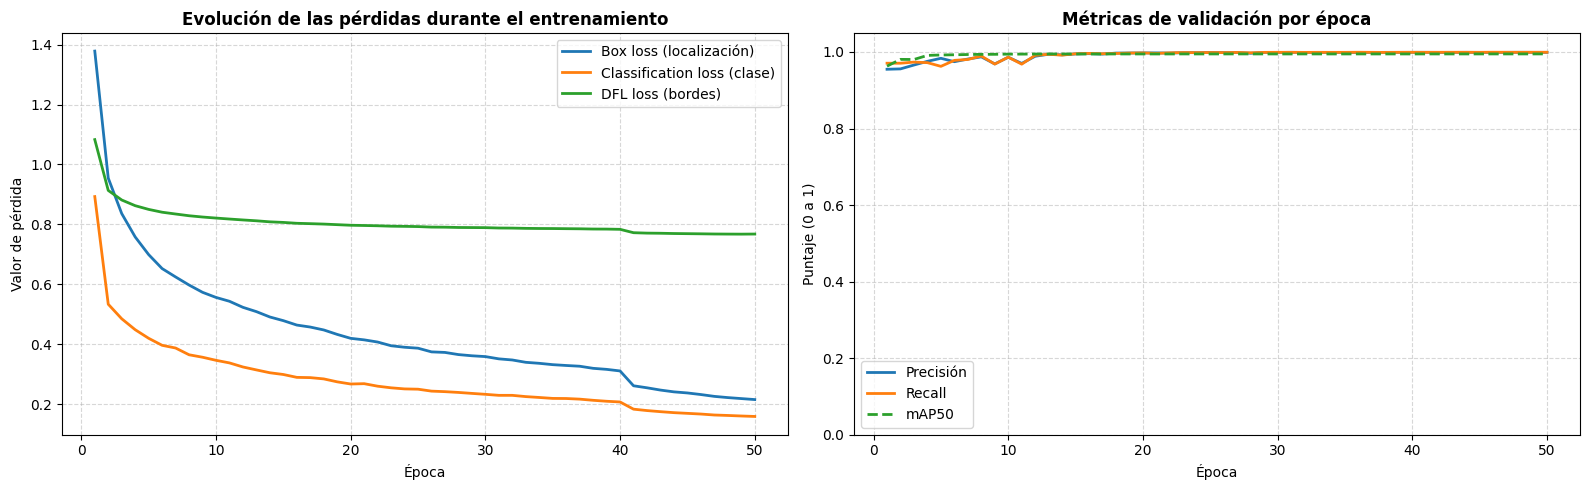

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar el archivo results.csv
df = pd.read_csv("/content/results.csv")
df.columns = df.columns.str.strip()  # Limpia espacios en los nombres de columnas

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Gráfico 1: Evolución de las pérdidas ---
axes[0].plot(df["epoch"], df["train/box_loss"], label="Box loss (localización)", linewidth=2)
axes[0].plot(df["epoch"], df["train/cls_loss"], label="Classification loss (clase)", linewidth=2)
axes[0].plot(df["epoch"], df["train/dfl_loss"], label="DFL loss (bordes)", linewidth=2)
axes[0].set_title("Evolución de las pérdidas durante el entrenamiento", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Valor de pérdida")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# --- Gráfico 2: Evolución de métricas en validación ---
axes[1].plot(df["epoch"], df["metrics/precision(B)"], label="Precisión", linewidth=2)
axes[1].plot(df["epoch"], df["metrics/recall(B)"], label="Recall", linewidth=2)
axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50", linewidth=2, linestyle="--")
axes[1].set_title("Métricas de validación por época", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Puntaje (0 a 1)")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("graficas_entrenamiento_espanol.png", dpi=200)
plt.show()

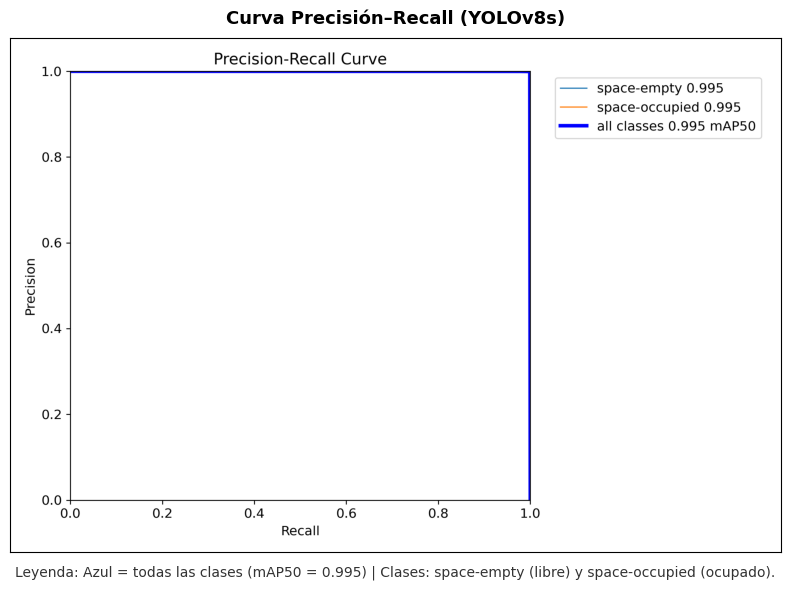

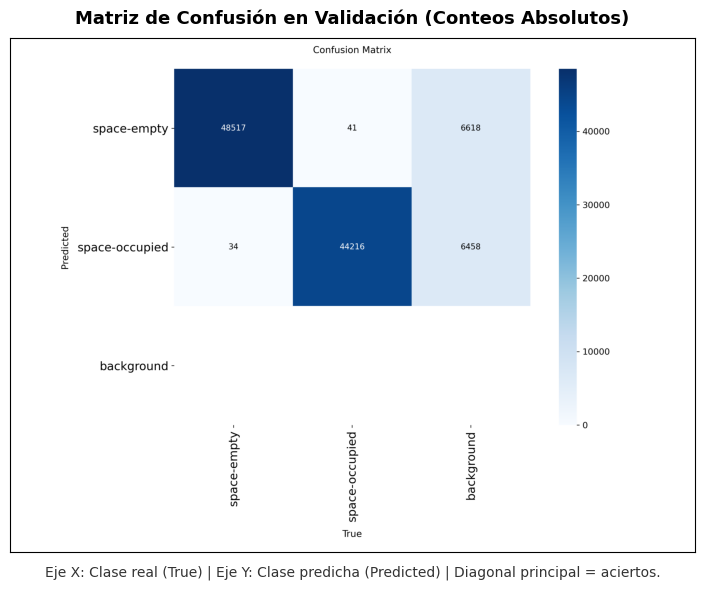

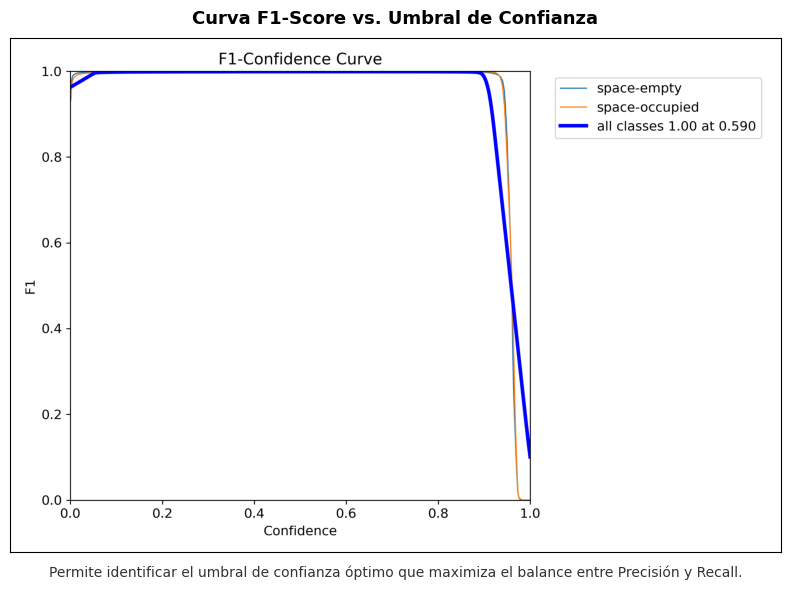

In [ ]:
import cv2
import matplotlib.pyplot as plt

imagenes_yolo = [
    ("/content/BoxPR_curve.png",
     "Curva Precisión–Recall (YOLOv8s)",
     "Leyenda: Azul = todas las clases (mAP50 = 0.995) | Clases: space-empty (libre) y space-occupied (ocupado)."),

    ("/content/confusion_matrix.png",
     "Matriz de Confusión en Validación (Conteos Absolutos)",
     "Eje X: Clase real (True) | Eje Y: Clase predicha (Predicted) | Diagonal principal = aciertos."),

    ("/content/BoxF1_curve.png",
     "Curva F1-Score vs. Umbral de Confianza",
     "Permite identificar el umbral de confianza óptimo que maximiza el balance entre Precisión y Recall.")
]

for archivo, titulo, leyenda in imagenes_yolo:
    img = cv2.cvtColor(cv2.imread(archivo), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.title(titulo, fontsize=13, fontweight="bold", pad=10)
    plt.xlabel(leyenda, fontsize=10, color="#333333", labelpad=10)
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
    plt.show()

**Interpretación de métricas:**

**Análisis de la Curva Precisión–Recall:** El modelo alcanza un **mAP50 global de 0.995**, con un desempeño idéntico de **0.995** tanto para espacios libres (`space-empty`) como para espacios ocupados (`space-occupied`). La curva pegada a la esquina superior derecha confirma que el detector mantiene una precisión cercana al 100% incluso a niveles máximos de *recall*.

**Análisis de la Matriz de Confusión:** El modelo clasifica correctamente **48 517** cajones libres y **44 216** cajones ocupados. La confusión directa entre clases es mínima: apenas **41** espacios ocupados predichos como libres y **34** libres predichos como ocupados. Los valores en la columna `background` (6 618 y 6 458) corresponden a detecciones en zonas del estacionamiento que no contaban con etiqueta en el *ground truth* o a cajas excedentes con baja confianza.

**Análisis de la Curva F1–Confianza:** Ambas clases alcanzan un **F1-Score máximo de 1.00** en el umbral de confianza óptimo de **0.590**. Además, la curva mantiene una meseta estable cercana a 1.00 en todo el rango de confianza entre **0.10 y 0.90**, lo que demuestra que el modelo es muy robusto y poco sensible a variaciones en el umbral de filtrado.

## 4. Pruebas Cualitativas en Escenarios Reales
Se define una función de inferencia utilizando los pesos óptimos (`best.pt`) que dibuja las cajas delimitadoras (verde = libre, rojo = ocupado), muestra el nivel de confianza y calcula el porcentaje de ocupación global.

In [ ]:
from ultralytics.utils.plotting import plot_results
from IPython.display import display, Image
import os

carpeta = "/content/runs/detect/Proyecto_Estacionamientos/modelo_small_50"
csv = f"{carpeta}/results.csv"

if os.path.isfile(csv):
    plot_results(file=csv)
    display(Image(filename=f"{carpeta}/results.png"))
else:
    print("No se encontró results.csv")

In [ ]:
import glob, cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('/content/best.pt')

def probar_por_fecha(prefijo_fecha, titulo_caso, conf_umbral=0.35, iou_umbral=0.65):
    coincidencias = glob.glob(f"/content/runs/test/{prefijo_fecha}*")
    if not coincidencias:
        print(f"No se encontró ninguna imagen que empiece con: {prefijo_fecha}")
        return

    ruta = coincidencias[0]
    img_orig = cv2.imread(ruta)
    img = img_orig.copy()
    resultados = model.predict(source=img, conf=conf_umbral, iou=iou_umbral, verbose=False)

    ocupados, libres = 0, 0
    fuente, escala, grosor = cv2.FONT_HERSHEY_SIMPLEX, 0.35, 1

    for box in resultados[0].boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf, cls = float(box.conf[0]), int(box.cls[0])

        if cls == 0:
            color, etiqueta = (0, 255, 0), f"Libre {int(conf*100)}%"
            libres += 1
        else:
            color, etiqueta = (0, 0, 255), f"Ocupado {int(conf*100)}%"
            ocupados += 1

        cv2.rectangle(img, (x1, y1), (x2, y2), color, 1)
        (w, h), _ = cv2.getTextSize(etiqueta, fuente, escala, grosor)
        cv2.rectangle(img, (x1, y1 - h - 4), (x1 + w + 2, y1), color, -1)
        cv2.putText(img, etiqueta, (x1 + 1, y1 - 2), fuente, escala, (0, 0, 0), grosor)

    total = ocupados + libres
    porc = (ocupados / total * 100) if total > 0 else 0.0
    img_final = cv2.copyMakeBorder(img, 50, 0, 0, 0, cv2.BORDER_CONSTANT, value=[0, 0, 0])
    stats = f"Total: {total} | Libres: {libres} | Ocupados: {ocupados} | Ocupacion: {porc:.1f}%"
    escala_stats, grosor_stats = 0.38, 1
    (w_txt, _), _ = cv2.getTextSize(stats, fuente, escala_stats, grosor_stats)
    pos_x = max(5, (img_final.shape[1] - w_txt) // 2)
    cv2.putText(img_final, stats, (pos_x, 30), fuente, escala_stats, (255, 255, 255), grosor_stats, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5.5), dpi=140)
    axes[0].imshow(cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Imagen Original", fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(cv2.cvtColor(img_final, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Detección YOLOv8s", fontweight="bold")
    axes[1].axis("off")

    plt.suptitle(titulo_caso, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

**Análisis Caso 1:** YOLOv8s detecta **40 espacios libres y 0 ocupados (0.0%)** con confianzas entre **94% y 97%**, sin generar falsos positivos por las sombras proyectadas sobre el asfalto.

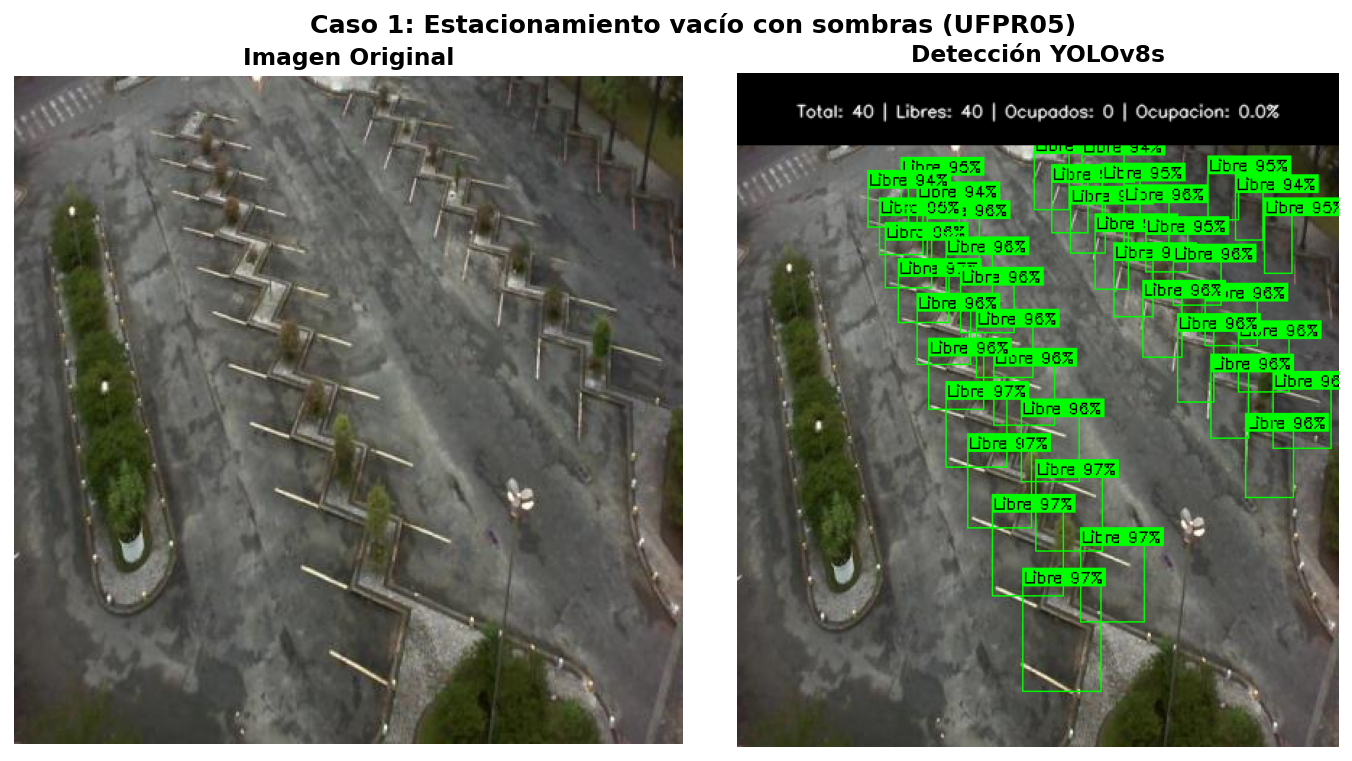

In [ ]:
probar_por_fecha("2013-03-12_06_40_00", "Caso 1: Estacionamiento vacío con sombras (UFPR05)")

**Análisis Caso 2:** Se identifican **40 espacios ocupados y 0 libres (100% de ocupación)** con confianzas superiores al **95%**, resolviendo adecuadamente autos oscuros con color similar al asfalto y filas densas.

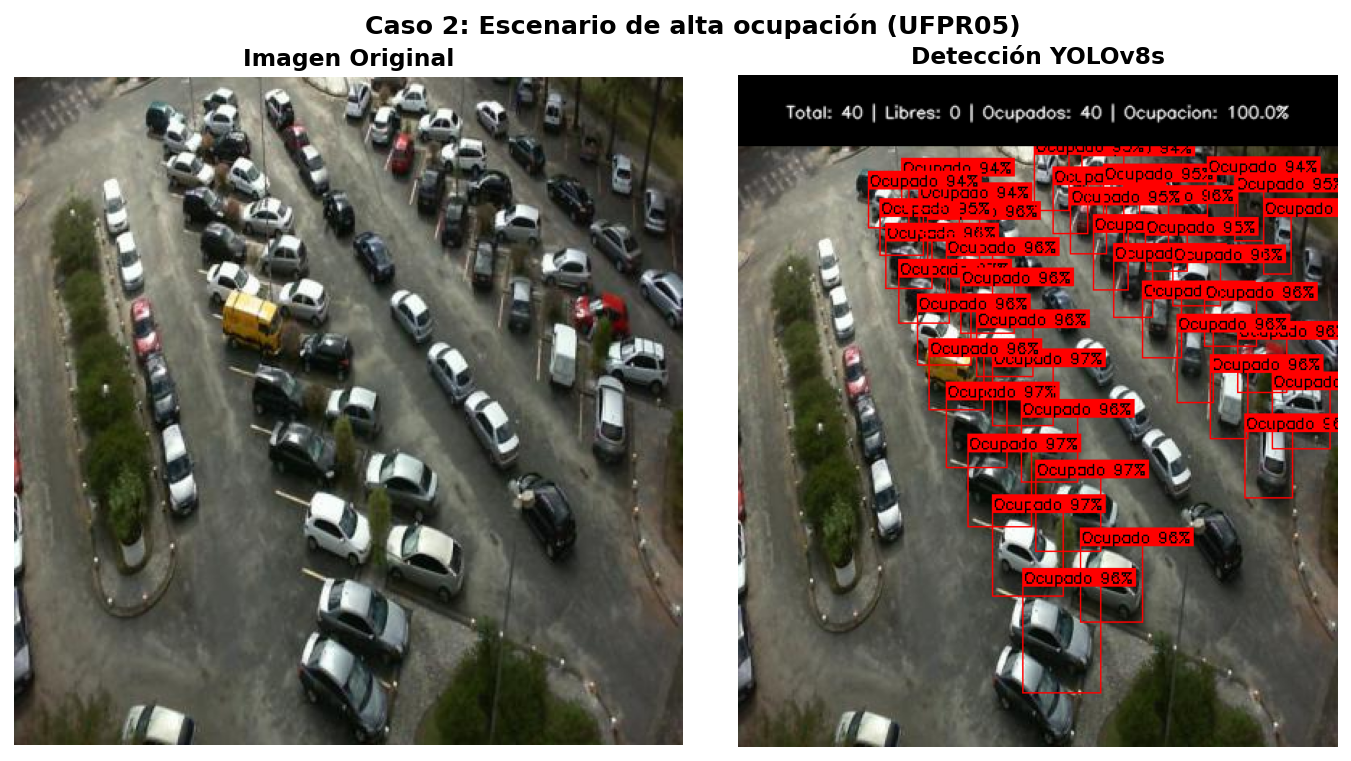

In [ ]:
probar_por_fecha("2013-04-10_10_45_05", "Caso 2: Escenario de alta ocupación (UFPR05)")

**Análisis Caso 3:** YOLOv8s estima **15 ocupados y 25 libres (37.5% de ocupación)** con confianzas entre **94% y 97%**, frente al **40.0%** del enfoque clásico, logrando localizar cada cajón sin coordenadas fijas predefinidas.

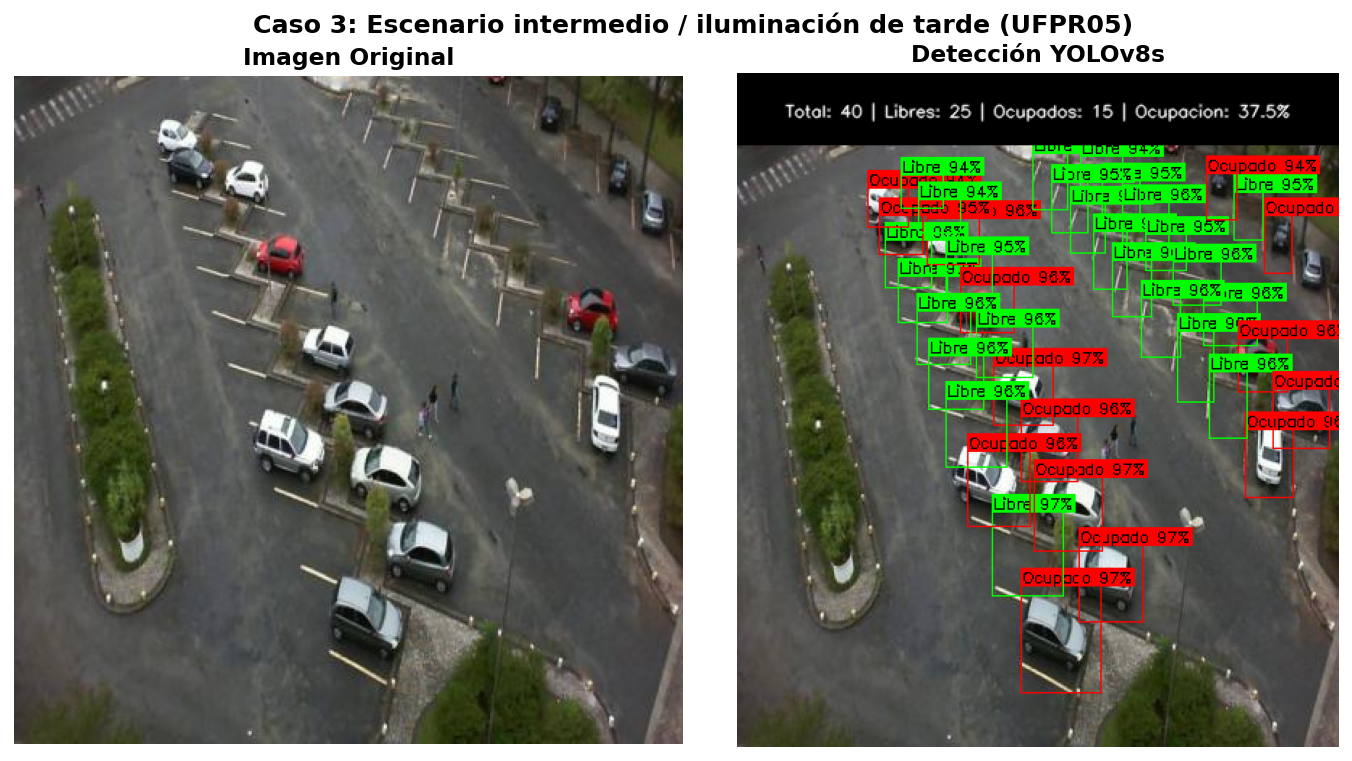

In [ ]:
probar_por_fecha("2013-03-15_07_25_01", "Caso 3: Escenario intermedio / iluminación de tarde (UFPR05)")

## 5. Conclusiones y Mejoras Futuras (Enfoque 2: YOLOv8s)

### Conclusiones
1. **Convergencia y desempeño sobresaliente:** El modelo **YOLOv8s** entrenado durante 50 épocas alcanzó una convergencia estable sin indicios de sobreajuste, logrando un **mAP50 de 0.995** tanto para `space-empty` como para `space-occupied`, y un **F1-Score máximo de 1.00** en el umbral óptimo de confianza de **0.590** (con una meseta estable entre 0.10 y 0.90).
2. **Mínima confusión entre clases:** La matriz de confusión confirma **48 517** cajones libres y **44 216** ocupados clasificados correctamente, registrando una confusión directa casi nula entre ambas clases (solo 41 ocupados predichos como libres y 34 libres como ocupados).
3. **Robustez fotométrica y autonomía:** A diferencia del procesamiento clásico (F1-Score de 0.95, vulnerable a sombras largas y dependiente de mapas de coordenadas fijas por cámara), YOLOv8s localiza y clasifica cada cajón de forma autónoma, manteniendo confianzas entre **93% y 97%** incluso en escenarios vacíos con sombras proyectadas.

### Limitaciones y Mejoras Futuras
* **Reducción de solapamiento en cajones diagonales:** Al emplear cajas alineadas a los ejes en cámaras con perspectiva inclinada, dos vehículos adyacentes pueden superponerse y fusionarse en el filtrado NMS. Como mejora se propone calibrar el umbral `iou` de NMS y migrar a **YOLOv8s-OBB** (*Oriented Bounding Boxes*) para alinear las cajas con el ángulo real de cada cajón.
* **Control de detecciones en el fondo (*background*):** Los conteos en la columna `background` de la matriz de confusión (6 618 y 6 458) reflejan detecciones en zonas del estacionamiento fuera de las anotaciones de referencia o cajas con baja confianza. Utilizar un umbral cercano al óptimo de la curva F1 (`conf ≈ 0.50–0.59`) y definir una máscara perimetral del área monitoreada reduciría estas detecciones excedentes.
* **Generalización a nuevos escenarios:** Evaluar el modelo en estacionamientos no vistos durante el entrenamiento (cámaras con distinta altura o tomas aéreas con dron) e incorporar imágenes nocturnas para operar las 24 horas.

In [ ]:
# Si lo subiste manualmente a /content/:
!jupyter nbconvert --to html "/content/pid_2.ipynb"

# (O si montaste Drive, usa esta ruta en su lugar):
# from google.colab import drive
# drive.mount('/content/drive')
# !jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/pid_2.ipynb"

[NbConvertApp] Converting notebook /content/pid_2.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 4749715 bytes to /content/pid_2.html
